# 10. Write a python program to generate image histograms and perform histogram equalization

In [241]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [242]:
img = cv2.imread("image.jpeg", cv2.IMREAD_GRAYSCALE)

In [243]:
height, width = img.shape

In [244]:
histogram = [0] * 256
for i in range(height):
    for j in range(width):
        histogram[img[i][j]] += 1

In [245]:
pdf = [0] * 256
for i in range(256):
    pdf[i] = histogram[i] / (height * width)

In [246]:
cdf = [0] * 256
cdf[0] = pdf[0]
for i in range(1, 256):
    cdf[i] = cdf[i-1] + pdf[i]

In [247]:
cdf = np.array(cdf)
cdf = cdf * 255

In [248]:
equalize_histogram_level = cdf.astype("uint8")

In [249]:
equalize_histogram = [0] * 256
for i in range(256):
    equalize_histogram[equalize_histogram_level[i]] += histogram[i] 

<BarContainer object of 256 artists>

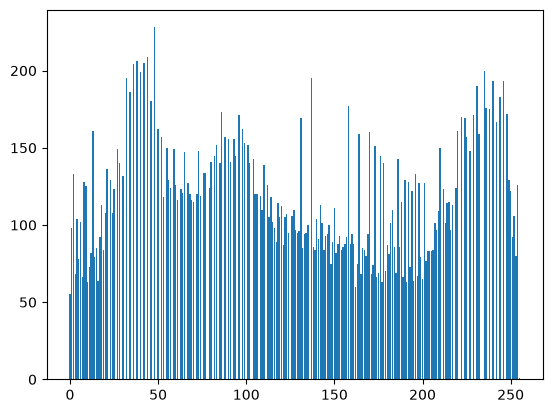

In [250]:
plt.bar(range(256), equalize_histogram)

Text(0.5, 1.0, 'Equalize Histogram')

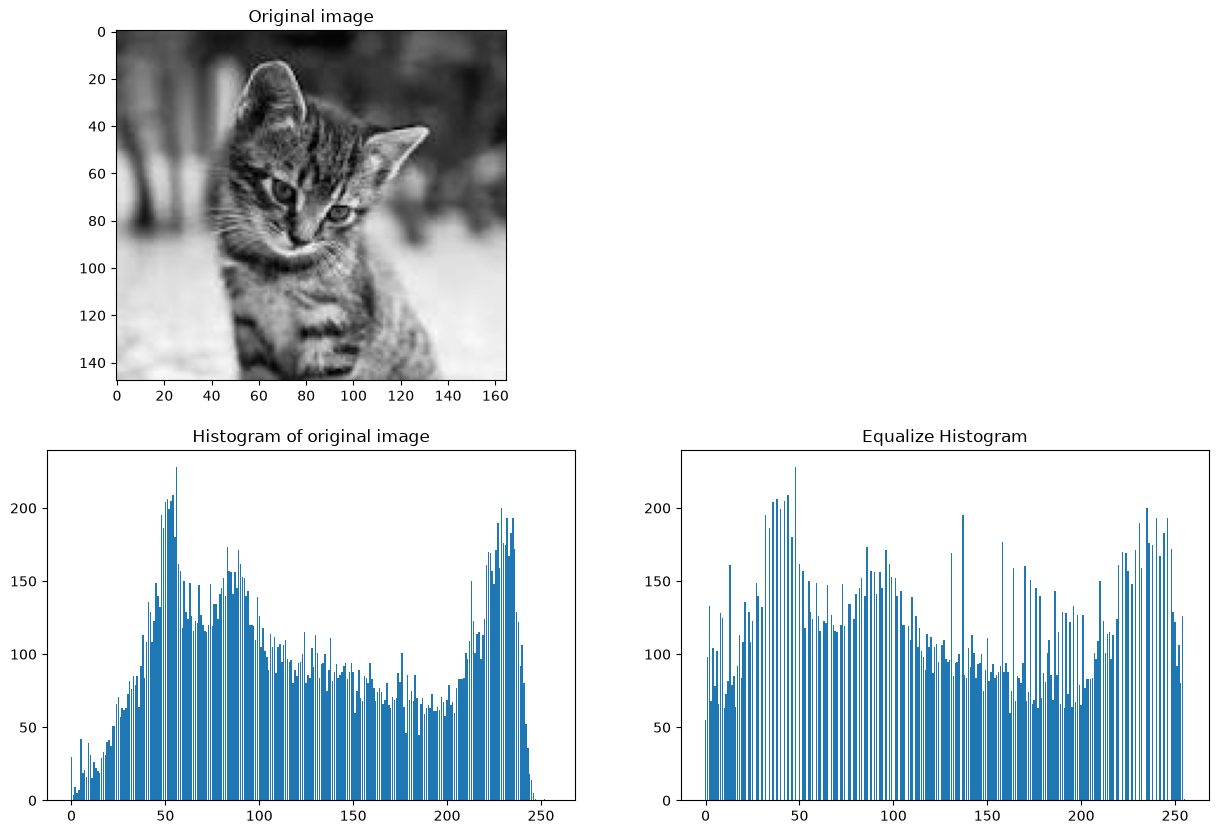

In [252]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original image")

plt.subplot(2, 2, 3)
plt.bar(range(256), histogram)
plt.title("Histogram of original image")

plt.subplot(2, 2, 4)
plt.bar(range(256), equalize_histogram)
plt.title("Equalize Histogram")